# Analisis de ElectricityLoadDiagrams20112014

## Introduccion
Este cuaderno analiza el dataset ElectricityLoadDiagrams20112014, que contiene mediciones de consumo electrico para multiples clientes (MT_001 a MT_370) en intervalos de 15 minutos entre 2011 y 2014.

El objetivo principal es entender el comportamiento temporal de la demanda electrica y separar:
- datos temporales base: marca de tiempo y consumo agregado
- valores marcados: picos de demanda, valles extremos y outliers
- metricas derivadas: resumenes por periodo y eventos relevantes

## Preguntas que responde este analisis
- Como cambia la carga por hora, dia, semana y mes
- Que clientes aportan mayor consumo total
- En que momentos ocurren los eventos criticos
- Cual es la estacionalidad dominante y su variacion

## Enfoque del cuaderno
- limpieza y tipado temporal
- transformacion wide a long para analisis por cliente
- deteccion de valores extremos con percentiles, IQR y z-score
- visualizaciones 2D y 3D para interpretar patrones de forma intuitiva

## 1. Cargar librerias y leer ElectricityLoadDiagrams20112014

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (14, 5)

# Ruta relativa al notebook (carpeta Practica_1)
data_path = Path('electricityloaddiagrams20112014/LD2011_2014.txt')

# El dataset usa ';' como separador y ',' como decimal
raw_df = pd.read_csv(
    data_path,
    sep=';',
    decimal=',',
    quotechar='"',
    parse_dates=[0],
    low_memory=False
)

# Renombrar la primera columna temporal (en origen aparece como "")
raw_df = raw_df.rename(columns={raw_df.columns[0]: 'timestamp'})

print(f'Dimensiones originales: {raw_df.shape}')
raw_df.head()

Dimensiones originales: (140256, 371)


,timestamp,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
0,2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Inspeccion rapida y perfilado del dataset

In [2]:
raw_df.info()

print('\nResumen estadistico (primeras 10 columnas de clientes):')
client_cols_preview = [c for c in raw_df.columns if c != 'timestamp'][:10]
display(raw_df[['timestamp'] + client_cols_preview].describe(include='all').T)

null_count = raw_df.isna().sum().sort_values(ascending=False)
print('\nTop columnas con nulos:')
display(null_count.head(10))

print(f'Numero de columnas de clientes: {len([c for c in raw_df.columns if c != "timestamp"])}')

<class 'pandas.DataFrame'>
RangeIndex: 140256 entries, 0 to 140255
Columns: 371 entries, timestamp to MT_370
dtypes: datetime64[us](1), float64(370)
memory usage: 397.0 MB

Resumen estadistico (primeras 10 columnas de clientes):


,count,mean,min,25%,50%,75%,max,std
timestamp,140256,2012-12-31 12:07:30,2011-01-01 00:15:00,2012-01-01 06:11:15,2012-12-31 12:07:30,2013-12-31 18:03:45,2015-01-01 00:00:00,NaN
MT_001,140256.0,3.970785,0.0,0.0,1.269036,2.538071,48.22335,5.983965
MT_002,140256.0,20.76848,0.0,2.84495,24.893314,29.871977,115.220484,13.272415
MT_003,140256.0,2.918308,0.0,0.0,1.737619,1.737619,151.172893,11.014456
MT_004,140256.0,82.18449,0.0,36.585366,87.398374,115.853659,321.138211,58.248392
MT_005,140256.0,37.240309,0.0,15.853659,39.02439,54.878049,150.0,26.461327
MT_006,140256.0,141.227385,0.0,71.428571,157.738095,205.357143,535.714286,98.439984
MT_007,140256.0,4.521338,0.0,0.565291,2.826456,4.522329,44.657999,6.485684
MT_008,140256.0,191.401476,0.0,111.111111,222.222222,279.461279,552.188552,121.981187
MT_009,140256.0,39.975354,0.0,13.986014,40.20979,57.692308,157.342657,29.814595



Top columnas con nulos:


timestamp    0
MT_001       0
MT_002       0
MT_003       0
MT_004       0
MT_005       0
MT_006       0
MT_007       0
MT_008       0
MT_009       0
dtype: int64

Numero de columnas de clientes: 370


## 3. Limpieza y tipado de variables temporales

In [3]:
df = raw_df.copy()

# Validacion de timestamp y orden cronologico
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp']).sort_values('timestamp').drop_duplicates(subset=['timestamp'])

# Convertir valores de clientes a numerico por seguridad
client_cols = [c for c in df.columns if c != 'timestamp']
df[client_cols] = df[client_cols].apply(pd.to_numeric, errors='coerce')

# Tratamiento basico de faltantes
missing_before = df[client_cols].isna().sum().sum()
df[client_cols] = df[client_cols].fillna(0)
missing_after = df[client_cols].isna().sum().sum()

# Frecuencia esperada: 15 minutos
delta = df['timestamp'].diff().dropna()
freq_mode = delta.mode().iloc[0] if not delta.empty else pd.Timedelta(0)

print(f'Dimensiones tras limpieza: {df.shape}')
print(f'Nulos en clientes antes: {missing_before:,} | despues: {missing_after:,}')
print(f'Frecuencia temporal mas comun: {freq_mode}')

Dimensiones tras limpieza: (140256, 371)
Nulos en clientes antes: 0 | despues: 0
Frecuencia temporal mas comun: 0 days 00:15:00


## 4. Reestructuracion de datos (wide -> long) para analisis temporal

In [4]:
# El dataset completo en largo puede ser muy pesado. Para analisis visual rapido,
# usamos los clientes con mayor energia total.
client_energy = df[client_cols].sum().sort_values(ascending=False)
top_clients_for_long = client_energy.head(30).index.tolist()

long_df = df[['timestamp'] + top_clients_for_long].melt(
    id_vars='timestamp',
    var_name='cliente',
    value_name='carga'
)

print(f'Formato long (top 30 clientes): {long_df.shape}')
long_df.head()

Formato long (top 30 clientes): (4207680, 3)


,timestamp,cliente,carga
0,2011-01-01 00:15:00,MT_362,0.0
1,2011-01-01 00:30:00,MT_362,0.0
2,2011-01-01 00:45:00,MT_362,0.0
3,2011-01-01 01:00:00,MT_362,0.0
4,2011-01-01 01:15:00,MT_362,0.0


## 5. Ingenieria de variables de tiempo (hora, dia, semana, mes, estacion)

In [5]:
def month_to_season(month: int) -> str:
    if month in (12, 1, 2):
        return 'invierno'
    if month in (3, 4, 5):
        return 'primavera'
    if month in (6, 7, 8):
        return 'verano'
    return 'otono'

temporal_df = df[['timestamp']].copy()
temporal_df['anio'] = temporal_df['timestamp'].dt.year
temporal_df['mes'] = temporal_df['timestamp'].dt.month
temporal_df['dia'] = temporal_df['timestamp'].dt.day
temporal_df['hora'] = temporal_df['timestamp'].dt.hour
temporal_df['dia_semana'] = temporal_df['timestamp'].dt.day_name()
temporal_df['es_fin_de_semana'] = temporal_df['timestamp'].dt.dayofweek >= 5
temporal_df['semana_del_anio'] = temporal_df['timestamp'].dt.isocalendar().week.astype(int)
temporal_df['estacion'] = temporal_df['mes'].map(month_to_season)

display(temporal_df.head())

,timestamp,anio,mes,dia,hora,dia_semana,es_fin_de_semana,semana_del_anio,estacion
0,2011-01-01 00:15:00,2011,1,1,0,Saturday,True,52,invierno
1,2011-01-01 00:30:00,2011,1,1,0,Saturday,True,52,invierno
2,2011-01-01 00:45:00,2011,1,1,0,Saturday,True,52,invierno
3,2011-01-01 01:00:00,2011,1,1,1,Saturday,True,52,invierno
4,2011-01-01 01:15:00,2011,1,1,1,Saturday,True,52,invierno


## 6. Analisis exploratorio de consumo global y por cliente

In [6]:
df['consumo_total'] = df[client_cols].sum(axis=1)
df['consumo_promedio_clientes'] = df[client_cols].mean(axis=1)

client_stats = pd.DataFrame({
    'energia_total': df[client_cols].sum(),
    'media': df[client_cols].mean(),
    'desviacion_std': df[client_cols].std(),
    'maximo': df[client_cols].max(),
    'minimo': df[client_cols].min()
}).sort_values('energia_total', ascending=False)

print('Top 10 clientes por energia total:')
display(client_stats.head(10))

print('Estadisticas globales de consumo_total:')
display(df['consumo_total'].describe())

/tmp/ipykernel_110942/3144173249.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['consumo_total'] = df[client_cols].sum(axis=1)
/tmp/ipykernel_110942/3144173249.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['consumo_promedio_clientes'] = df[client_cols].mean(axis=1)


Top 10 clientes por energia total:


,energia_total,media,desviacion_std,maximo,minimo
MT_362,5.274746e+09,37607.987537,38691.954832,192800.000000,0.0
MT_196,2.909492e+09,20744.150874,7339.107947,78541.666667,0.0
MT_279,1.688538e+09,12038.971232,3130.464062,21414.166667,0.0
MT_370,1.223363e+09,8722.355145,9195.155777,30918.918919,0.0
MT_208,9.343897e+08,6662.030067,2081.556920,14218.487395,0.0
MT_228,8.110523e+08,5782.656826,1967.855665,10473.684211,0.0
MT_220,4.139586e+08,2951.449898,1229.487553,7075.949367,0.0
MT_364,4.123571e+08,2940.031734,2732.251967,12386.363636,0.0
MT_194,3.751848e+08,2675.000006,909.523209,6038.135593,0.0
MT_241,3.670313e+08,2616.867076,772.020840,5061.728395,0.0


Estadisticas globales de consumo_total:


count    140256.000000
mean     195556.942526
std       84259.360145
min         342.595509
25%      131128.411567
50%      167856.513526
75%      248834.303388
max      452652.595567
Name: consumo_total, dtype: float64

## 7. Deteccion de valores marcados (picos, valles y outliers)

In [7]:
# Umbrales por percentiles sobre el consumo total
p95 = df['consumo_total'].quantile(0.95)
p99 = df['consumo_total'].quantile(0.99)

# Z-score robusto para detectar eventos extremos
mean_total = df['consumo_total'].mean()
std_total = df['consumo_total'].std(ddof=0)
df['zscore_total'] = (df['consumo_total'] - mean_total) / std_total if std_total != 0 else 0

# IQR para outliers
q1 = df['consumo_total'].quantile(0.25)
q3 = df['consumo_total'].quantile(0.75)
iqr = q3 - q1
low_iqr = q1 - 1.5 * iqr
high_iqr = q3 + 1.5 * iqr

peak_events = df[df['consumo_total'] >= p99][['timestamp', 'consumo_total', 'zscore_total']].copy()
peak_events['tipo'] = 'pico_p99'

valley_events = df.nsmallest(30, 'consumo_total')[['timestamp', 'consumo_total', 'zscore_total']].copy()
valley_events['tipo'] = 'valle_extremo'

outlier_events = df[(df['consumo_total'] < low_iqr) | (df['consumo_total'] > high_iqr)][['timestamp', 'consumo_total', 'zscore_total']].copy()
outlier_events['tipo'] = 'outlier_iqr'

important_events = pd.concat([peak_events, valley_events, outlier_events], ignore_index=True)
important_events = important_events.drop_duplicates().sort_values(['tipo', 'consumo_total'], ascending=[True, False])

print(f'p95={p95:.2f} | p99={p99:.2f} | outliers_iqr={len(outlier_events)}')
display(important_events.head(20))

p95=362649.83 | p99=402775.46 | outliers_iqr=296


/tmp/ipykernel_110942/2821587426.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['zscore_total'] = (df['consumo_total'] - mean_total) / std_total if std_total != 0 else 0


,timestamp,consumo_total,zscore_total,tipo
1622,2013-07-09 17:00:00,452652.595567,3.051252,outlier_iqr
1623,2013-07-09 17:15:00,451274.659339,3.034899,outlier_iqr
1460,2012-08-10 16:00:00,450761.237309,3.028805,outlier_iqr
1613,2013-07-09 14:45:00,449864.761971,3.018166,outlier_iqr
1465,2012-08-10 17:15:00,449004.850322,3.007960,outlier_iqr
1619,2013-07-09 16:15:00,448724.130303,3.004629,outlier_iqr
1461,2012-08-10 16:15:00,448500.631865,3.001976,outlier_iqr
1464,2012-08-10 17:00:00,448483.518814,3.001773,outlier_iqr
1616,2013-07-09 15:30:00,448452.017932,3.001399,outlier_iqr
1492,2012-08-21 16:15:00,448124.746545,2.997515,outlier_iqr


## 8. Separacion de datos temporales vs metricas derivadas

In [8]:
# Datos temporales base: timestamp + consumo total
base_temporal = df[['timestamp', 'consumo_total']].copy()

# Metricas importantes: eventos marcados + resumen por periodo
period_summary = (
    df.set_index('timestamp')['consumo_total']
    .resample('D')
    .agg(['sum', 'mean', 'max', 'min', 'std'])
    .rename(columns={'sum': 'consumo_diario', 'mean': 'promedio_diario', 'max': 'max_diario', 'min': 'min_diario', 'std': 'std_diario'})
    .reset_index()
)

important_metrics = important_events.merge(
    period_summary,
    left_on=important_events['timestamp'].dt.floor('D'),
    right_on=period_summary['timestamp'],
    how='left',
    suffixes=('', '_dia')
)

# Limpieza de columnas duplicadas por merge
important_metrics = important_metrics.drop(columns=['key_0', 'timestamp_dia'], errors='ignore')

print('Base temporal (muestra):')
display(base_temporal.head())
print('Metricas importantes (muestra):')
display(important_metrics.head())

Base temporal (muestra):


,timestamp,consumo_total
0,2011-01-01 00:15:00,68513.115338
1,2011-01-01 00:30:00,69180.304361
2,2011-01-01 00:45:00,69364.850573
3,2011-01-01 01:00:00,68350.480660
4,2011-01-01 01:15:00,66166.874303


Metricas importantes (muestra):


,timestamp,consumo_total,zscore_total,tipo,consumo_diario,promedio_diario,max_diario,min_diario,std_diario
0,2013-07-09 17:00:00,452652.595567,3.051252,outlier_iqr,3.015923e+07,314158.600864,452652.595567,140651.281697,122155.609869
1,2013-07-09 17:15:00,451274.659339,3.034899,outlier_iqr,3.015923e+07,314158.600864,452652.595567,140651.281697,122155.609869
2,2012-08-10 16:00:00,450761.237309,3.028805,outlier_iqr,2.874148e+07,299390.435025,450761.237309,119424.903180,129610.810657
3,2013-07-09 14:45:00,449864.761971,3.018166,outlier_iqr,3.015923e+07,314158.600864,452652.595567,140651.281697,122155.609869
4,2012-08-10 17:15:00,449004.850322,3.007960,outlier_iqr,2.874148e+07,299390.435025,450761.237309,119424.903180,129610.810657


## 9. Visualizaciones clave de series temporales

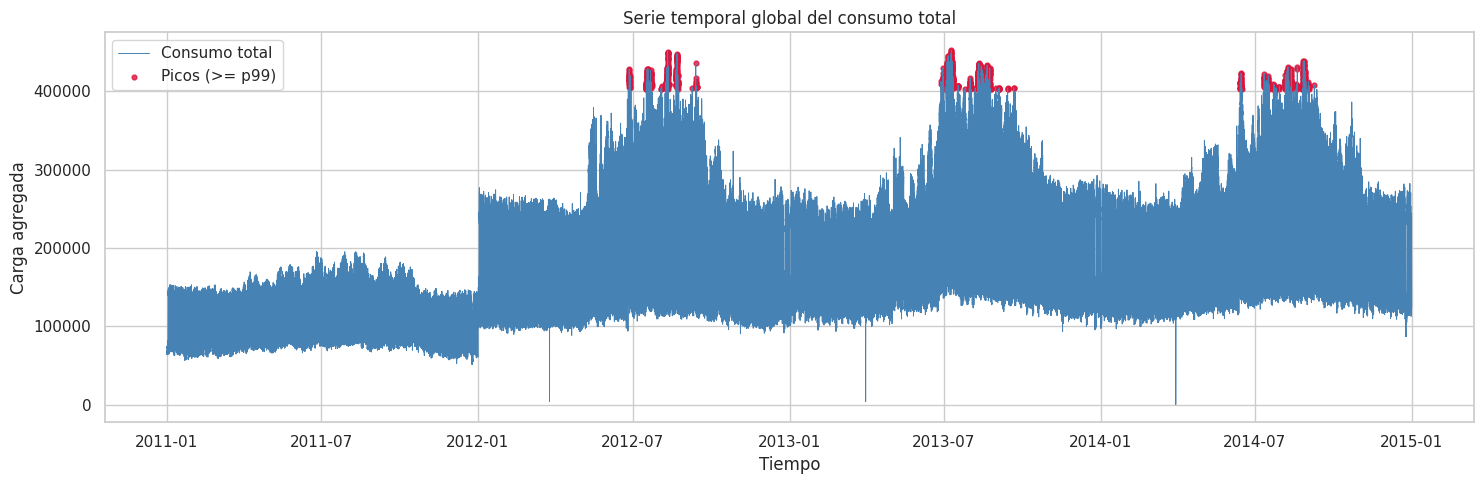

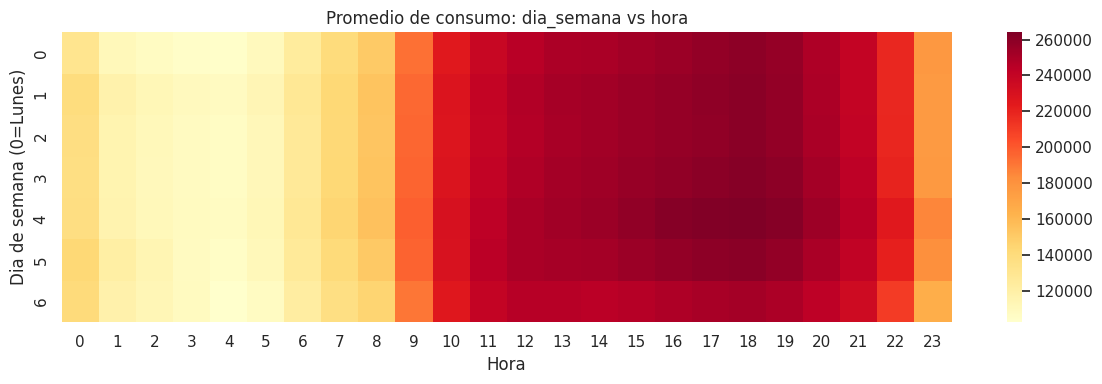

/tmp/ipykernel_110942/451629726.py:35: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sns.boxplot(data=df.assign(hora=df['timestamp'].dt.hour), x='hora', y='consumo_total', ax=axes[0], fliersize=1)
/tmp/ipykernel_110942/451629726.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sns.boxplot(data=df.assign(mes=df['timestamp'].dt.month), x='mes', y='consumo_total', ax=axes[1], fliersize=1)


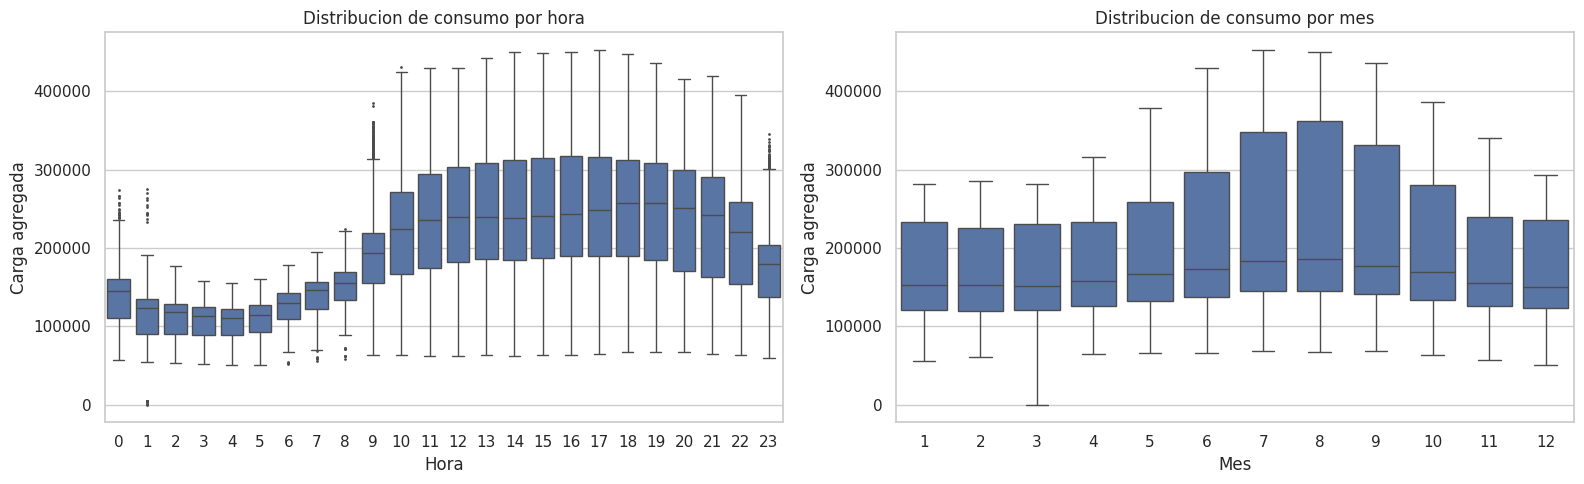

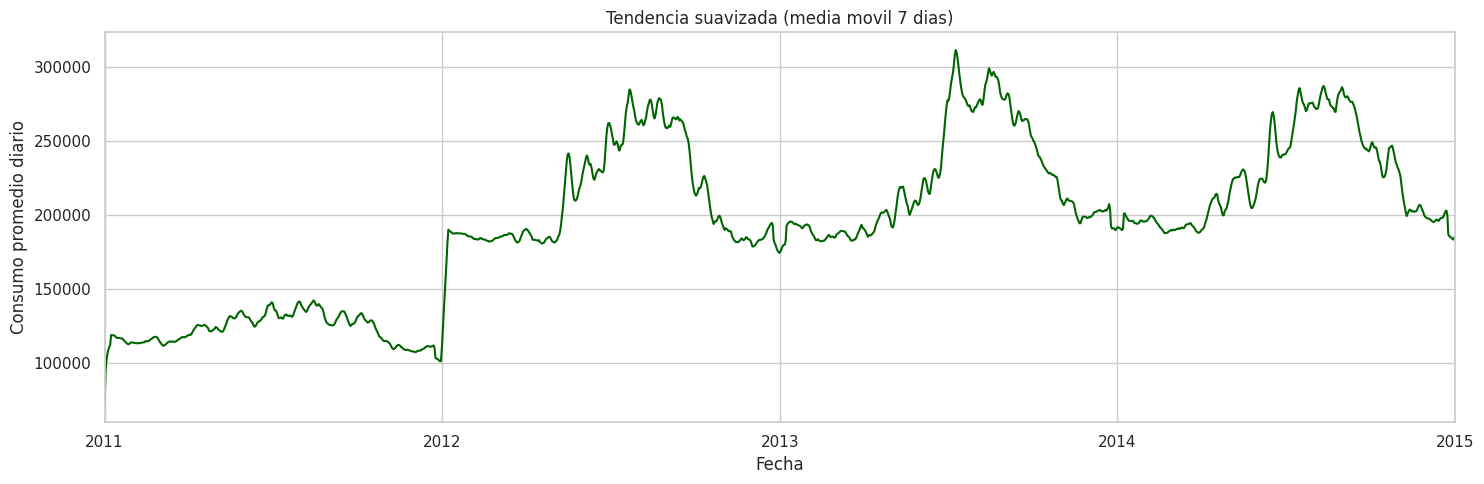

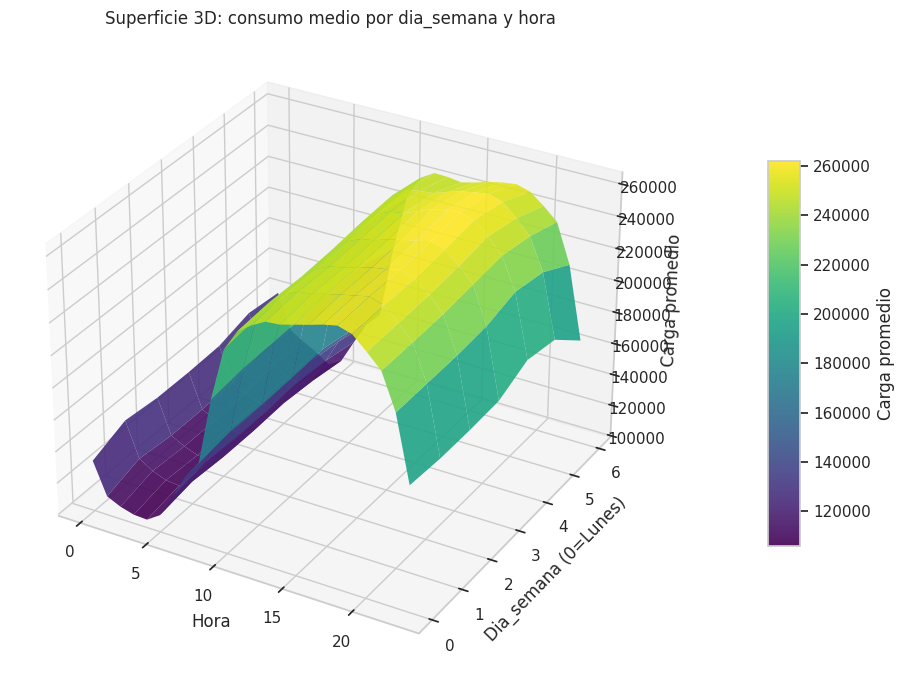

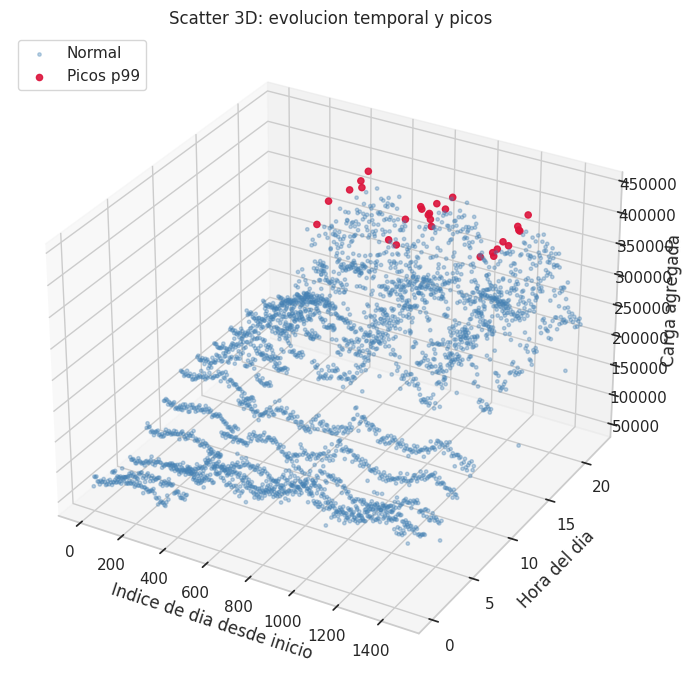

In [12]:
# Linea temporal global con picos p99
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df['timestamp'], df['consumo_total'], linewidth=0.7, color='steelblue', label='Consumo total')
ax.scatter(
    peak_events['timestamp'],
    peak_events['consumo_total'],
    color='crimson',
    s=12,
    alpha=0.8,
    label='Picos (>= p99)'
)
ax.set_title('Serie temporal global del consumo total')
ax.set_xlabel('Tiempo')
ax.set_ylabel('Carga agregada')
ax.legend()
plt.tight_layout()
plt.show()

# Heatmap: hora vs dia de la semana
df_heat = df[['timestamp', 'consumo_total']].copy()
df_heat['hora'] = df_heat['timestamp'].dt.hour
df_heat['dia_semana'] = df_heat['timestamp'].dt.dayofweek
heat_matrix = df_heat.pivot_table(values='consumo_total', index='dia_semana', columns='hora', aggfunc='mean')

plt.figure(figsize=(12, 4))
sns.heatmap(heat_matrix, cmap='YlOrRd')
plt.title('Promedio de consumo: dia_semana vs hora')
plt.xlabel('Hora')
plt.ylabel('Dia de semana (0=Lunes)')
plt.tight_layout()
plt.show()

# Boxplots por hora y por mes
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df.assign(hora=df['timestamp'].dt.hour), x='hora', y='consumo_total', ax=axes[0], fliersize=1)
axes[0].set_title('Distribucion de consumo por hora')
axes[0].set_xlabel('Hora')
axes[0].set_ylabel('Carga agregada')

sns.boxplot(data=df.assign(mes=df['timestamp'].dt.month), x='mes', y='consumo_total', ax=axes[1], fliersize=1)
axes[1].set_title('Distribucion de consumo por mes')
axes[1].set_xlabel('Mes')
axes[1].set_ylabel('Carga agregada')

plt.tight_layout()
plt.show()

# Rolling mean para tendencia
rolling_daily = (
    df.set_index('timestamp')['consumo_total']
    .resample('D').mean()
    .rolling(7, min_periods=1)
    .mean()
)

plt.figure(figsize=(15, 5))
rolling_daily.plot(color='darkgreen')
plt.title('Tendencia suavizada (media movil 7 dias)')
plt.xlabel('Fecha')
plt.ylabel('Consumo promedio diario')
plt.tight_layout()
plt.show()

# Grafica 3D: superficie de consumo medio por dia_semana y hora
x_hours = np.arange(24)
y_days = np.arange(7)
X, Y = np.meshgrid(x_hours, y_days)
Z = heat_matrix.reindex(index=y_days, columns=x_hours).values

fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)
ax.set_title('Superficie 3D: consumo medio por dia_semana y hora')
ax.set_xlabel('Hora')
ax.set_ylabel('Dia_semana (0=Lunes)')
ax.set_zlabel('Carga promedio')
fig.colorbar(surf, shrink=0.6, aspect=12, pad=0.1, label='Carga promedio')
plt.tight_layout()
plt.show()

# Grafica 3D: nube temporal por hora del dia (muestra para rendimiento)
sample_3d = df[['timestamp', 'consumo_total']].copy()
sample_3d = sample_3d.iloc[::40].copy()
sample_3d['hora'] = sample_3d['timestamp'].dt.hour
sample_3d['dia_indice'] = (sample_3d['timestamp'] - sample_3d['timestamp'].min()).dt.days
sample_3d['is_peak'] = sample_3d['consumo_total'] >= p99

fig = plt.figure(figsize=(13, 7))
ax = fig.add_subplot(111, projection='3d')

normal = sample_3d[~sample_3d['is_peak']]
peaks = sample_3d[sample_3d['is_peak']]

ax.scatter(
    normal['dia_indice'],
    normal['hora'],
    normal['consumo_total'],
    c='steelblue',
    s=6,
    alpha=0.35,
    label='Normal'
)
ax.scatter(
    peaks['dia_indice'],
    peaks['hora'],
    peaks['consumo_total'],
    c='crimson',
    s=20,
    alpha=0.9,
    label='Picos p99'
)

ax.set_title('Scatter 3D: evolucion temporal y picos')
ax.set_xlabel('Indice de dia desde inicio')
ax.set_ylabel('Hora del dia')
ax.set_zlabel('Carga agregada')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 10. Rankings y graficos de los valores mas importantes

In [ ]:
# Top-N picos por cliente
top_peaks_by_client = (
    long_df.sort_values('carga', ascending=False)
    .groupby('cliente', as_index=False)
    .head(3)
    .sort_values('carga', ascending=False)
)

top_days = (
    df.set_index('timestamp')['consumo_total']
    .resample('D').sum()
    .sort_values(ascending=False)
    .head(15)
)

# Mayor variacion diaria (max-min)
daily_var = df.set_index('timestamp')['consumo_total'].resample('D').agg(lambda x: x.max() - x.min())
top_var_days = daily_var.sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 5))
sns.barplot(data=top_peaks_by_client.head(20), x='cliente', y='carga', color='tomato')
plt.title('Top 20 picos de carga (clientes destacados)')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
top_days.sort_values().plot(kind='barh', color='slateblue')
plt.title('Top dias de mayor demanda total')
plt.xlabel('Consumo diario total')
plt.ylabel('Dia')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
top_var_days.sort_values().plot(kind='barh', color='darkorange')
plt.title('Top dias con mayor variacion intradia')
plt.xlabel('Rango diario (max - min)')
plt.ylabel('Dia')
plt.tight_layout()
plt.show()

# Scatter para observaciones criticas
plt.figure(figsize=(15, 5))
plt.scatter(df['timestamp'], df['consumo_total'], s=6, alpha=0.25, label='Normal')
plt.scatter(important_events['timestamp'], important_events['consumo_total'], s=14, alpha=0.9, color='red', label='Marcados')
plt.title('Observaciones criticas sobre la serie completa')
plt.xlabel('Tiempo')
plt.ylabel('Carga agregada')
plt.legend()
plt.tight_layout()
plt.show()

## 11. Comparativas por granularidad temporal (hora/dia/mes)

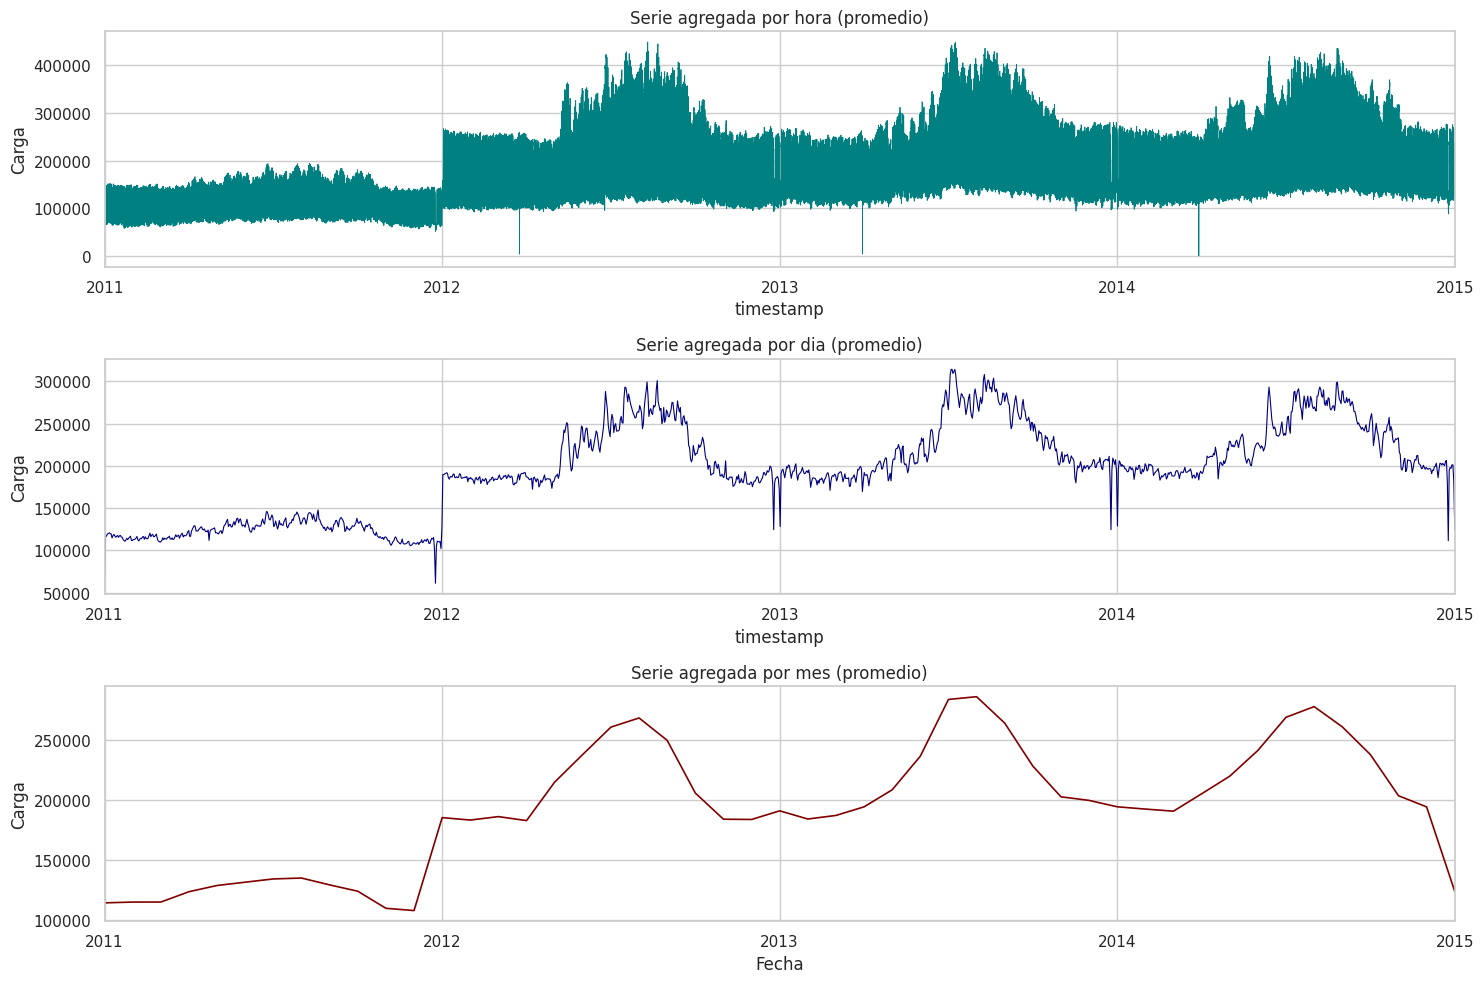

Cambio relativo diario (resumen):


count    1461.000000
mean        0.001843
std         0.057419
min        -0.389605
25%        -0.016422
50%         0.001547
75%         0.017369
max         0.747562
Name: consumo_total, dtype: float64

Cambio relativo mensual (resumen):


count    48.000000
mean      0.010262
std       0.141150
min      -0.361467
25%      -0.043061
50%       0.002888
75%       0.049326
max       0.715357
Name: consumo_total, dtype: float64

In [10]:
serie = df.set_index('timestamp')['consumo_total']

agg_hour = serie.resample('h').mean()
agg_day = serie.resample('D').mean()
agg_month = serie.resample('ME').mean()

change_day = agg_day.pct_change().replace([np.inf, -np.inf], np.nan)
change_month = agg_month.pct_change().replace([np.inf, -np.inf], np.nan)

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=False)
agg_hour.plot(ax=axes[0], color='teal', linewidth=0.6)
axes[0].set_title('Serie agregada por hora (promedio)')
axes[0].set_ylabel('Carga')

agg_day.plot(ax=axes[1], color='navy', linewidth=0.8)
axes[1].set_title('Serie agregada por dia (promedio)')
axes[1].set_ylabel('Carga')

agg_month.plot(ax=axes[2], color='maroon', linewidth=1.2)
axes[2].set_title('Serie agregada por mes (promedio)')
axes[2].set_ylabel('Carga')
axes[2].set_xlabel('Fecha')

plt.tight_layout()
plt.show()

print('Cambio relativo diario (resumen):')
display(change_day.describe())
print('Cambio relativo mensual (resumen):')
display(change_month.describe())

## 12. Guardar datasets procesados y figuras

Parquet exportado correctamente.


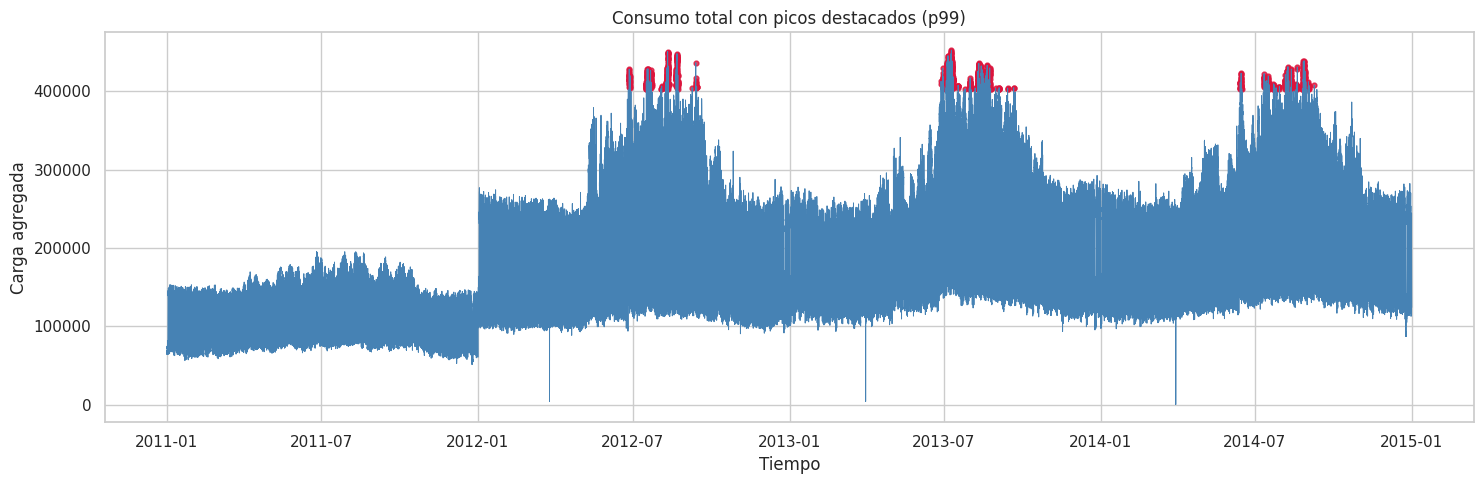

Archivos guardados en: /home/michi/Documents/Aprendizaje Automatico/Practica_1/resultados
- datos_temporales_base.csv / .parquet
- metricas_importantes.csv / .parquet
- resumen_periodico_diario.csv / .parquet
- figuras/consumo_total_con_picos.png


In [11]:
output_dir = Path('resultados')
fig_dir = output_dir / 'figuras'
output_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

# Guardar datasets procesados
base_temporal.to_csv(output_dir / 'datos_temporales_base.csv', index=False)
important_metrics.to_csv(output_dir / 'metricas_importantes.csv', index=False)
period_summary.to_csv(output_dir / 'resumen_periodico_diario.csv', index=False)

# Parquet opcional (si pyarrow/fastparquet esta instalado)
try:
    base_temporal.to_parquet(output_dir / 'datos_temporales_base.parquet', index=False)
    important_metrics.to_parquet(output_dir / 'metricas_importantes.parquet', index=False)
    period_summary.to_parquet(output_dir / 'resumen_periodico_diario.parquet', index=False)
    print('Parquet exportado correctamente.')
except Exception as e:
    print(f'No se pudo exportar Parquet (opcional): {e}')

# Regenerar y guardar una figura clave
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df['timestamp'], df['consumo_total'], linewidth=0.7, color='steelblue')
ax.scatter(peak_events['timestamp'], peak_events['consumo_total'], color='crimson', s=12, alpha=0.8)
ax.set_title('Consumo total con picos destacados (p99)')
ax.set_xlabel('Tiempo')
ax.set_ylabel('Carga agregada')
fig.tight_layout()
fig.savefig(fig_dir / 'consumo_total_con_picos.png', dpi=150)
plt.show()

print('Archivos guardados en:', output_dir.resolve())
print('- datos_temporales_base.csv / .parquet')
print('- metricas_importantes.csv / .parquet')
print('- resumen_periodico_diario.csv / .parquet')
print('- figuras/consumo_total_con_picos.png')